#  Exploratory Data Analysis (EDA)

Use the cleaned dataset from Task 02. This task explores the sales data to discover patterns, trends, relationships, and business insights.

## Upload Proceed data

In [3]:
from google.colab import files
uploaded = files.upload()

Saving cleaned_customers.csv to cleaned_customers.csv
Saving cleaned_merged_dataset.csv to cleaned_merged_dataset.csv
Saving cleaned_orders.csv to cleaned_orders.csv
Saving cleaned_products.csv to cleaned_products.csv
Saving cleaning_summary.csv to cleaning_summary.csv
Saving order_level_dataset.csv to order_level_dataset.csv


##  Import libraries and load data

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

# Updated path to load the file from the root directory where it was uploaded
analysis_data = pd.read_csv(
    "cleaned_merged_dataset.csv"
)

analysis_data["order_date"] = pd.to_datetime(
    analysis_data["order_date"]
)

print("Dataset loaded:", analysis_data.shape)
display(analysis_data.head())

Dataset loaded: (4352, 37)


,order_item_id,order_id,order_date,customer_id,product_id,quantity,unit_list_price_gbp,discount_pct,unit_selling_price_gbp,shipping_mode,...,avg_rating,review_count,year,month,month_name,day,day_name,weekday,is_weekend,profit_margin_pct
0,ITEM-01850,ORD-01353,2026-01-01,C-0455,AMZ-4001,1,21.99,0,21.99,Standard Delivery,...,4.6,1340,2026,1,January,1,Thursday,3,False,61.969576
1,ITEM-01526,ORD-01112,2026-01-01,C-0237,AMZ-2001,1,84.99,0,84.99,Standard Delivery,...,4.7,1640,2026,1,January,1,Thursday,3,False,57.376677
2,ITEM-01396,ORD-01017,2026-01-01,C-0454,AMZ-1004,1,39.99,0,39.99,Next-Day Express,...,4.6,1890,2026,1,January,1,Thursday,3,False,56.647399
3,ITEM-00371,ORD-00269,2026-01-01,C-0795,AMZ-4002,1,69.99,10,62.99,Standard Delivery,...,4.5,490,2026,1,January,1,Thursday,3,False,55.289482
4,ITEM-03465,ORD-02546,2026-01-01,C-0075,AMZ-3003,1,10.99,10,9.89,Standard Delivery,...,4.5,2900,2026,1,January,1,Thursday,3,False,53.416149


##  Descriptive statistics

In [6]:
display(analysis_data.describe())

,order_date,quantity,unit_list_price_gbp,discount_pct,unit_selling_price_gbp,shipping_fee_gbp,total_revenue_gbp,total_cost_gbp,net_profit_gbp,customer_rating,unit_cost_gbp,list_price_gbp,avg_rating,review_count,year,month,day,weekday,profit_margin_pct
count,4352,4352.000000,4352.000000,4352.000000,4352.000000,4352.000000,4352.000000,4352.000000,4352.000000,1396.000000,4352.000000,4352.000000,4352.000000,4352.000000,4352.0,4352.000000,4352.000000,4352.000000,4352.000000
mean,2026-06-04 20:34:31.323529472,1.164982,41.278180,3.786765,39.692116,0.952123,47.160657,19.078814,25.971089,4.143983,16.389361,41.278180,4.610133,1787.925092,2026.0,5.632812,15.871324,2.974265,53.670636
min,2026-01-01 00:00:00,1.000000,10.990000,0.000000,7.690000,0.000000,7.690000,4.500000,0.690000,1.000000,4.500000,10.990000,4.300000,410.000000,2026.0,1.000000,1.000000,0.000000,8.972692
25%,2026-03-22 00:00:00,1.000000,18.990000,0.000000,18.990000,0.000000,21.980000,8.000000,11.490000,4.000000,6.500000,18.990000,4.500000,980.000000,2026.0,3.000000,9.000000,1.000000,50.990198
50%,2026-06-13 00:00:00,1.000000,27.990000,0.000000,27.990000,0.000000,33.240000,12.500000,17.990000,4.000000,11.000000,27.990000,4.600000,1580.000000,2026.0,6.000000,16.000000,3.000000,54.700553
75%,2026-08-09 00:00:00,1.000000,39.990000,5.000000,39.990000,2.990000,49.990000,22.000000,26.980000,5.000000,18.000000,39.990000,4.700000,2150.000000,2026.0,8.000000,23.000000,5.000000,58.180868
max,2026-10-31 00:00:00,3.000000,149.000000,30.000000,149.000000,4.990000,447.000000,186.000000,258.500000,5.000000,62.000000,149.000000,4.900000,4500.000000,2026.0,10.000000,31.000000,6.000000,70.490121
std,NaN,0.433472,34.066458,6.895719,32.987553,1.566700,44.499000,19.378821,25.431105,1.093500,14.405510,34.066458,0.152737,1091.480744,0.0,2.812506,8.439844,1.970894,7.219329


##  Revenue and profit summary

In [7]:
total_revenue = analysis_data["total_revenue_gbp"].sum()
total_profit = analysis_data["net_profit_gbp"].sum()
total_orders = analysis_data["order_id"].nunique()

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Profit: £{total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")

Total Revenue: £205,243.18
Total Profit: £113,026.18
Total Orders: 3,200


##  Monthly sales trends

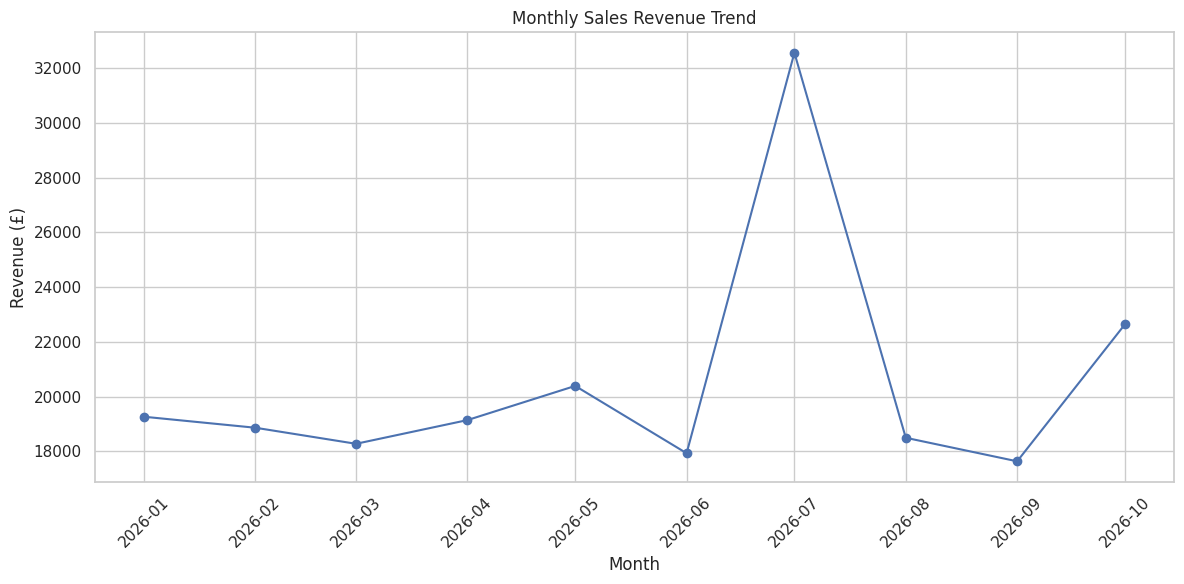

In [10]:
monthly_sales = (
    analysis_data.groupby(
        analysis_data["order_date"].dt.to_period("M")
    )["total_revenue_gbp"]
    .sum()
)

monthly_sales.index = monthly_sales.index.to_timestamp()

plt.figure(figsize=(12, 6))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()

# Automatically create the directories if they do not exist
os.makedirs("/content/reports/figures/eda/", exist_ok=True)

plt.savefig(
    "/content/reports/figures/eda/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

##  Sales distribution

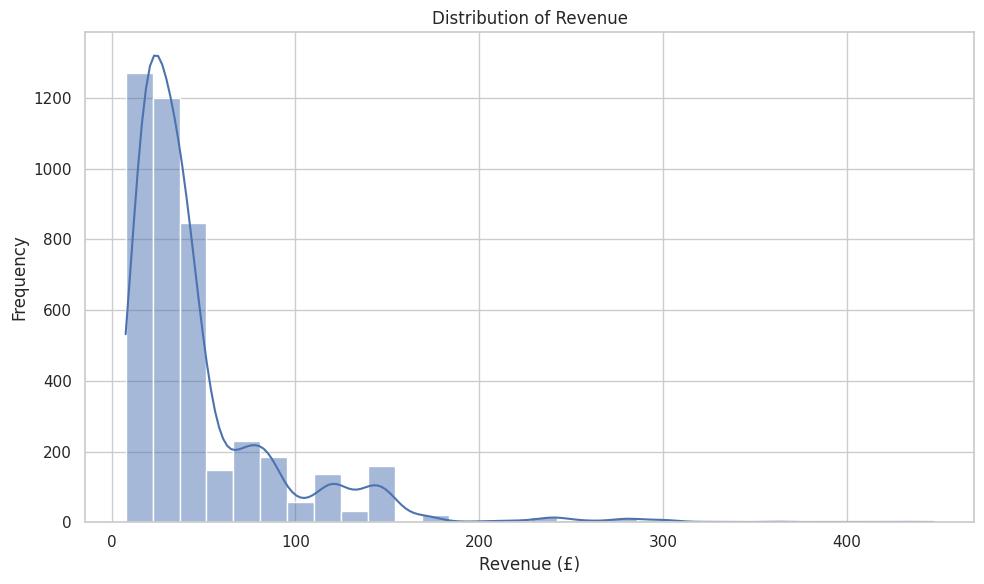

In [11]:
plt.figure(figsize=(10, 6))

sns.histplot(
    analysis_data["total_revenue_gbp"],
    bins=30,
    kde=True
)

plt.title("Distribution of Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

##  Boxplot of revenue

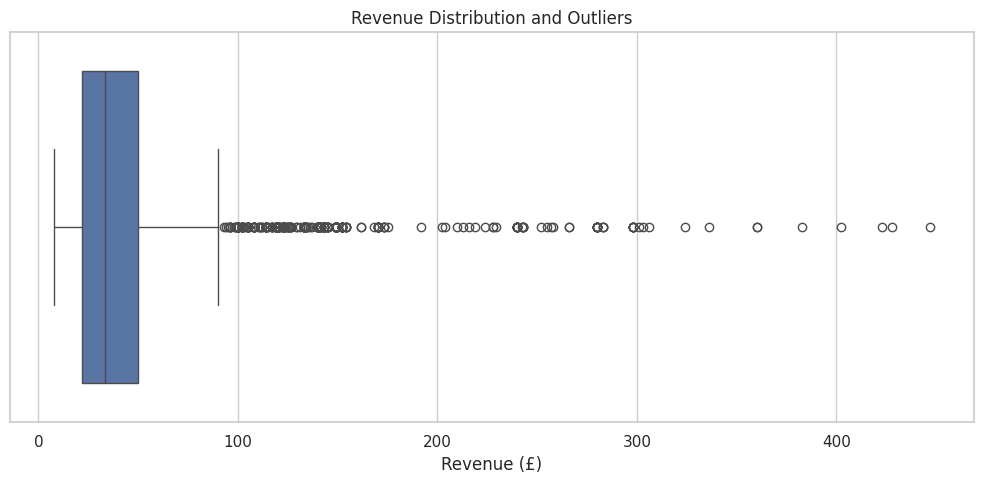

In [12]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=analysis_data["total_revenue_gbp"]
)

plt.title("Revenue Distribution and Outliers")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.show()

##  Quantity distribution

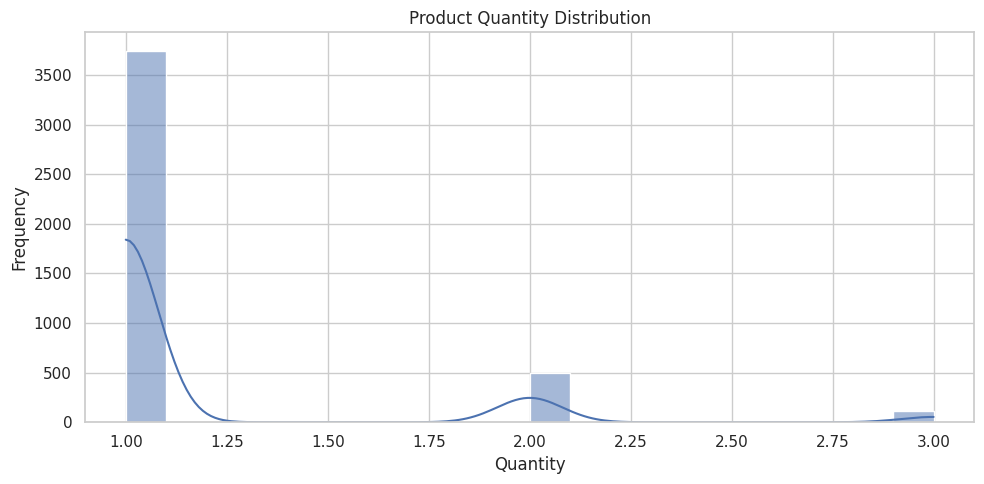

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    analysis_data["quantity"],
    bins=20,
    kde=True
)

plt.title("Product Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

##  Sales by category

Use the correct category column from the products dataset. After merging, it will usually be category.

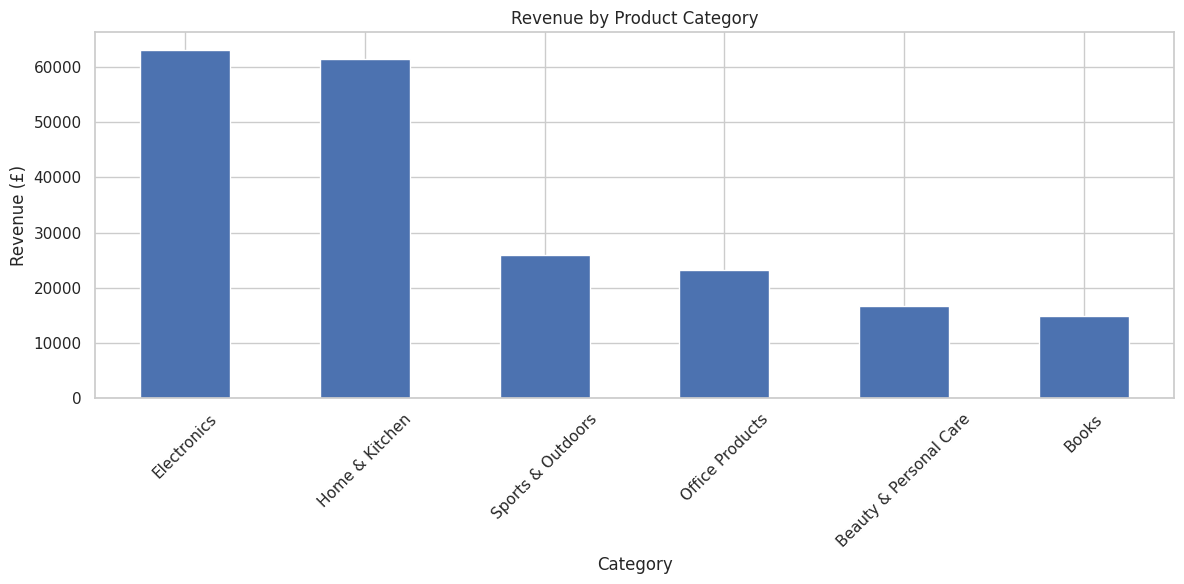

,total_revenue_gbp
category,
Electronics,63056.62
Home & Kitchen,61457.35
Sports & Outdoors,25959.91
Office Products,23280.30
Beauty & Personal Care,16656.06
Books,14832.94


In [14]:
category_sales = (
    analysis_data.groupby("category")["total_revenue_gbp"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
category_sales.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(category_sales)

##  Profit by category

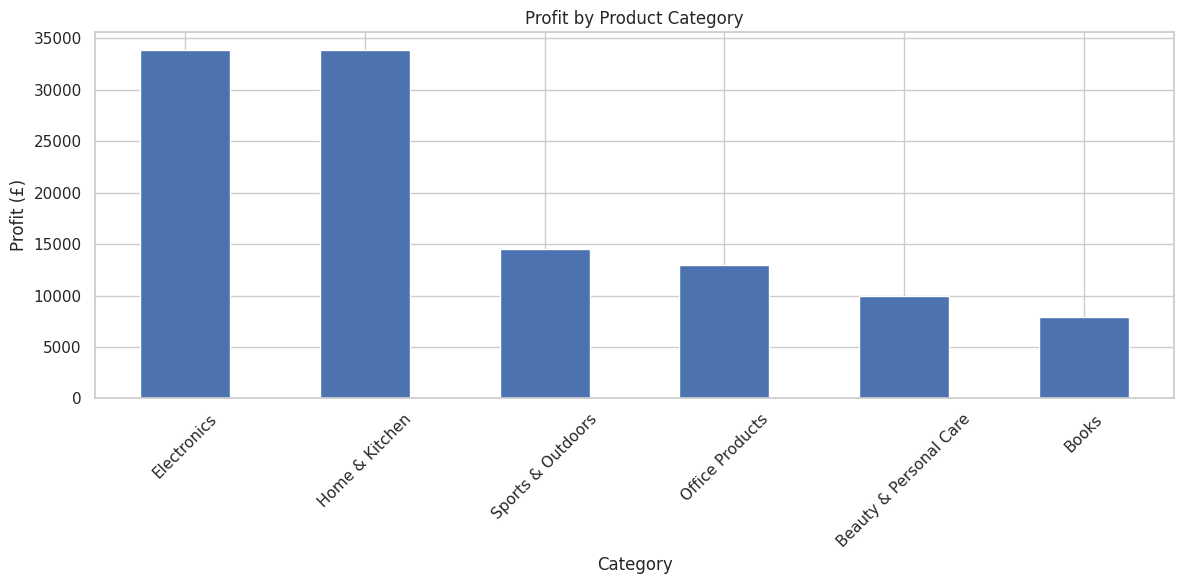

In [15]:
category_profit = (
    analysis_data.groupby("category")["net_profit_gbp"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
category_profit.plot(kind="bar")

plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##  Top 10 products by revenue

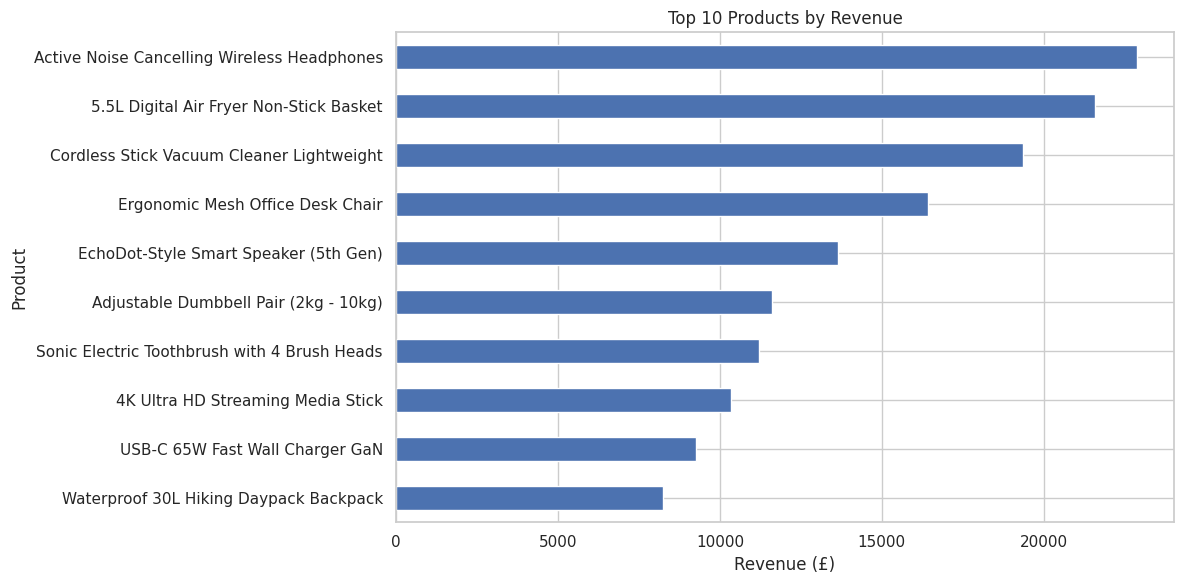

,total_revenue_gbp
product_name,
Active Noise Cancelling Wireless Headphones,22881.57
5.5L Digital Air Fryer Non-Stick Basket,21579.80
Cordless Stick Vacuum Cleaner Lightweight,19371.86
Ergonomic Mesh Office Desk Chair,16415.63
EchoDot-Style Smart Speaker (5th Gen),13647.08
Adjustable Dumbbell Pair (2kg - 10kg),11607.36
Sonic Electric Toothbrush with 4 Brush Heads,11193.39
4K Ultra HD Streaming Media Stick,10335.66
USB-C 65W Fast Wall Charger GaN,9270.70


In [16]:
top_products = (
    analysis_data.groupby("product_name")["total_revenue_gbp"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

display(top_products)

##  Revenue by region

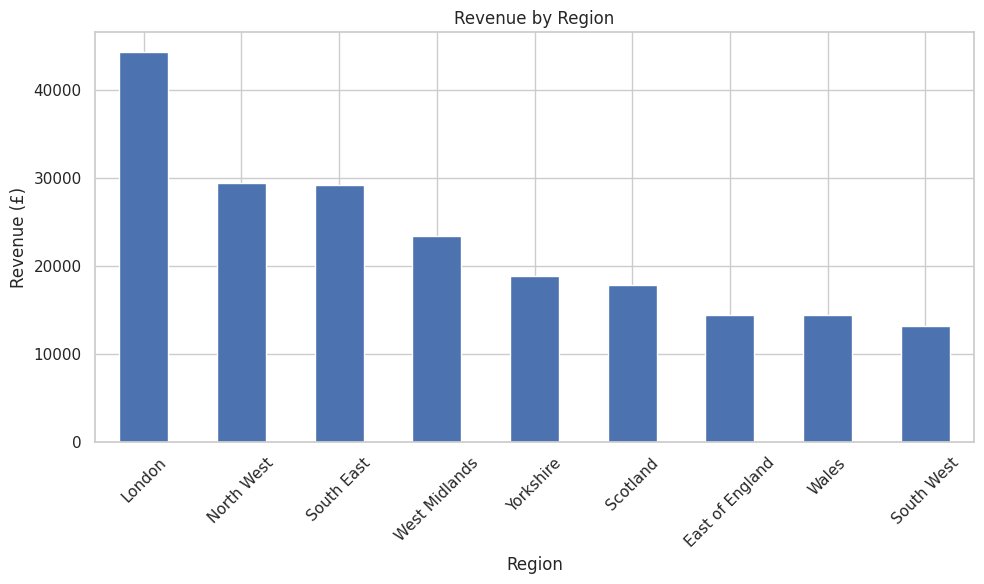

,total_revenue_gbp
region,
London,44380.26
North West,29429.64
South East,29194.84
West Midlands,23424.63
Yorkshire,18888.61
Scotland,17818.28
East of England,14425.72
Wales,14421.76
South West,13259.44


In [17]:
region_sales = (
    analysis_data.groupby("region")["total_revenue_gbp"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
region_sales.plot(kind="bar")

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(region_sales)

##  Discount versus revenue

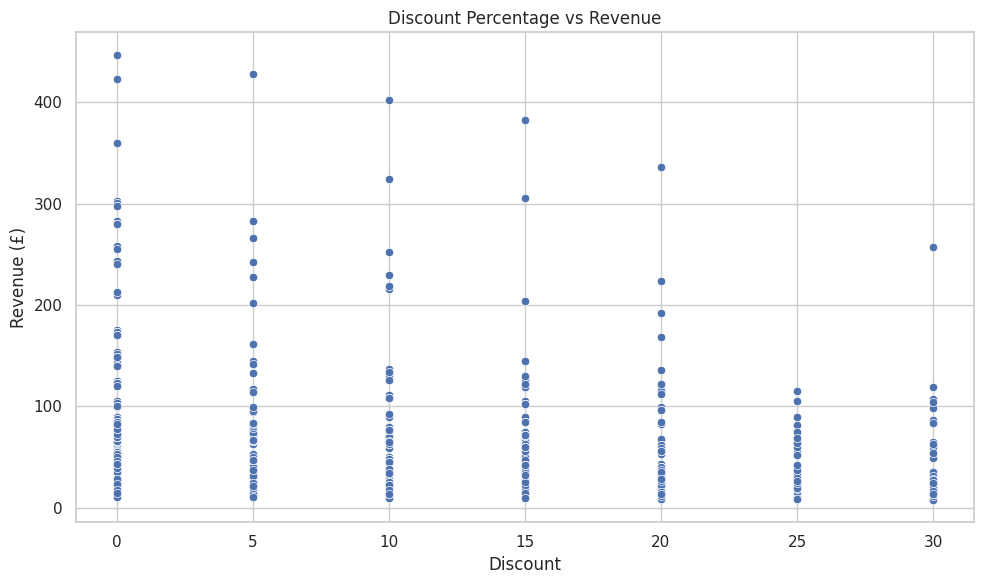

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=analysis_data,
    x="discount_pct",
    y="total_revenue_gbp"
)

plt.title("Discount Percentage vs Revenue")
plt.xlabel("Discount")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.show()

##  Discount versus profit

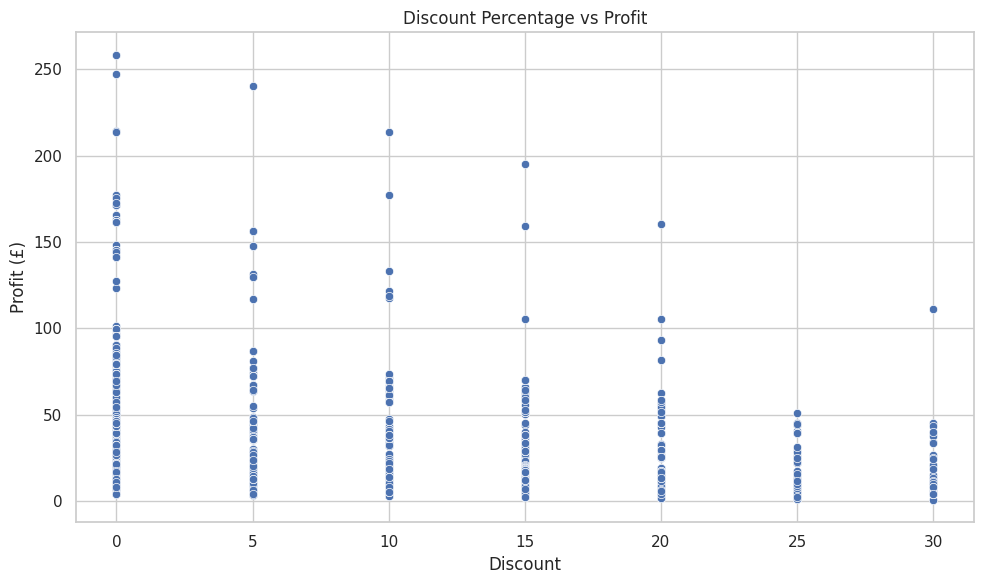

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=analysis_data,
    x="discount_pct",
    y="net_profit_gbp"
)

plt.title("Discount Percentage vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit (£)")
plt.tight_layout()
plt.show()

##  Correlation heatmap

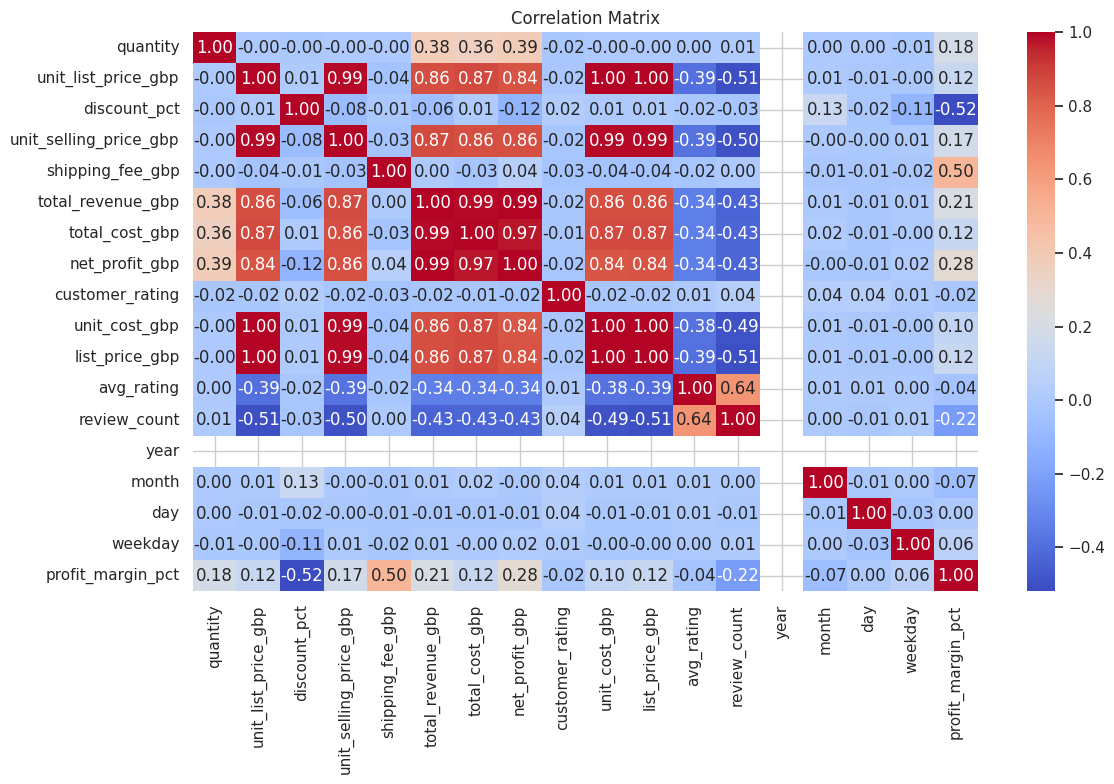

In [20]:
numeric_data = analysis_data.select_dtypes(
    include=np.number
)

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

##  Sales by day of week

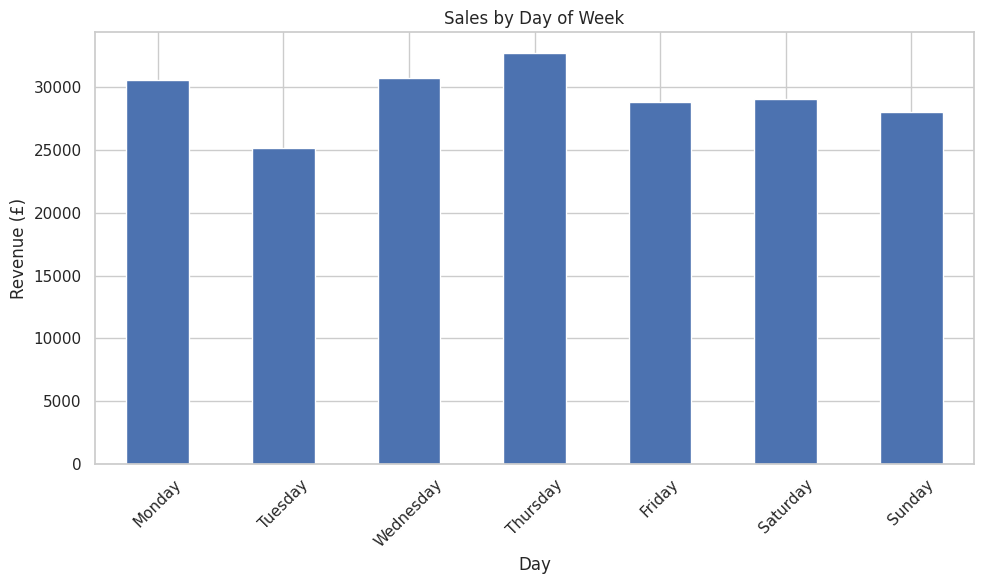

In [21]:
analysis_data["day_name"] = (
    analysis_data["order_date"].dt.day_name()
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    analysis_data.groupby("day_name")["total_revenue_gbp"]
    .sum()
    .reindex(weekday_order)
)

plt.figure(figsize=(10, 6))
weekday_sales.plot(kind="bar")

plt.title("Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##  Save EDA charts

In [22]:
os.makedirs("/content/reports/figures/eda", exist_ok=True)

In [23]:
plt.savefig(
    "/content/reports/figures/eda/chart_name.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

##  download File

In [25]:
files.download("/content/eda_visualizations.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>